# 5장 1강: 일반화와 학습 안정화 기법 — 실습문제

## 실습 목표

- 학습 손실과 검증 손실을 함께 보고 과적합의 징후를 설명합니다.
- Dropout과 Weight Decay가 각각 무엇을 바꾸는지 계산합니다.
- Batch Normalization의 학습·평가 시 동작 차이를 이해합니다.
- Early Stopping의 중단 시점과 최적 가중치 복원 시점을 구분합니다.

## 실습 환경 / 데이터

- Python, pandas, NumPy, Matplotlib을 사용합니다. 별도의 딥러닝 프레임워크는 필요하지 않습니다.
- **`concrete_data.csv`**를 노트북과 같은 폴더에 두고 실행하세요. 파일 이름이 `concrete_data(1).csv`인 경우에도 준비 코드가 읽을 수 있습니다.
- 원본은 1,030행, 9열이며 8개 입력 특성과 실제 압축강도 `concrete_compressive_strength`로 구성됩니다.
- 동일한 전체 행이 학습·검증에 중복으로 들어가는 것을 줄이기 위해 완전히 같은 25행을 제거합니다. 남은 1,005행을 고정된 난수 순서로 섞어 **학습 80행, 검증 200행**을 사용합니다. 나머지 725행은 이번 실습에서 사용하지 않습니다.
- 작은 학습 표본은 빠르게 학습 기록을 만들고 일반화 차이를 관찰하기 위한 교육용 설정입니다. 이 표본 수를 실제 프로젝트의 권장 비율로 제시하는 것은 아닙니다.
- 입력과 목표의 평균·표준편차는 **학습 80행에서만** 구하고 검증에도 같은 값을 적용합니다. 표준화와 학습 함수는 제공 코드이므로 새로 작성할 필요가 없습니다.
- 순서대로 셀을 실행하세요. 결과 표의 마지막 소수 자리는 실행 환경에 따라 조금 달라질 수 있습니다.

## 이번 강의의 범위

제공된 **5장 1강 목차: 과적합과 일반화, Dropout, Weight Decay, Batch Normalization, Early Stopping**을 기준으로 구성했습니다. 강의 본문은 별도로 제공되지 않았으므로 모델 크기·마스크·가중치·설정값은 원리를 확인하기 위해 정한 예시입니다.

**학습 상태 진단에는 Concrete 데이터로 실제 계산한 손실 기록**을 사용합니다. 데이터 준비·학습·중단 판단 함수는 제공하고, 학생은 호출·간단한 계산·해석을 수행합니다. 역전파 유도, 전체 학습 코드 구현, 최적 설정 탐색은 요구하지 않습니다.

Dropout·Weight Decay·Batch Normalization은 각각 작은 계산으로 동작을 확인합니다. 이 계산들이 진단용 모델의 학습에 적용된 것은 아니므로, 각 기법을 사용한 뒤 검증 성능이 좋아졌다고 주장하지 않습니다. 별도의 테스트 성능 평가도 수행하지 않습니다.

## 실습 구성

| 구분 | 문제 | 할 일 |
|---|---|---|
| 실습 1 | 1-1 | 실제 학습·검증 손실로 학습 상태 진단 |
| 실습 1 | 1-2 | Dropout과 Weight Decay의 계산 비교 |
| 실습 2 | 2-1 | Batch Normalization의 학습·평가 계산 |
| 실습 2 | 2-2 | Early Stopping 판단과 최적 가중치 복원 |
| 기초 과제 | 3-1 | 기다리는 횟수를 바꾸고 네 기법의 역할 정리 |

**실습 2개 + 기초 과제 1개**이며 세부 문항 수는 내용에 맞추어 구성했습니다.

## 시작 전에 읽을 용어

| 용어 | 쉽게 풀어쓴 뜻 |
|---|---|
| 일반화 | 학습에 쓰지 않은 새로운 데이터에도 예측이 잘 맞는 성질 |
| 과적합 | 학습 데이터에 지나치게 맞추어 새로운 데이터에 대한 성능이 충분히 좋아지지 않거나 나빠지는 상태 |
| 학습 데이터 | 가중치를 업데이트할 때 사용하는 데이터 |
| 검증 데이터 | 업데이트에 직접 사용하지 않고 학습 상태·설정을 판단하는 데이터 |
| Epoch | 학습 데이터를 한 차례 사용한 횟수. 이번 코드는 80행 전체로 한 번 업데이트 |
| MSE | 예측 오차를 제곱하여 평균한 손실. 작을수록 예측 오차가 작음 |
| Dropout | 학습 중 일부 활성값을 임시로 0으로 만드는 방식 |
| Weight Decay | 업데이트 때 가중치를 0 방향으로 줄이는 항을 추가하는 방식 |
| Batch | 함께 처리하는 여러 샘플의 묶음 |
| Batch Normalization, BN | 학습 중 배치의 특성별 통계로 값을 정규화하고 크기·위치를 조절하는 층 |
| gamma·beta | BN 결과의 크기와 위치를 조절하는 학습 가능한 값 |
| running mean·variance | 평가 때 사용할 수 있도록 학습 중 누적해 두는 평균·분산 |
| Early Stopping | 검증 성능이 정해진 기간 동안 개선되지 않으면 학습을 멈추는 규칙 |
| patience | 개선이 없을 때 기다릴 연속 횟수 |
| checkpoint | 특정 시점의 가중치·편향을 저장한 값 |

검증 결과로 시점이나 설정을 골랐다면 그 검증 데이터는 선택 과정에 관여한 것입니다. 새로운 데이터에서의 최종 성능은 별도로 남겨 둔 테스트 데이터로 확인해야 합니다.

### 처음 배우는 학생을 위한 출발점

Concrete 데이터의 한 행은 콘크리트 한 샘플의 재료·조건과 실제 압축강도를 담고 있습니다. 모델은 재료·조건을 입력받아 압축강도를 예측합니다. **이미 배운 샘플에 잘 맞추는 것과 처음 보는 샘플에도 잘 맞추는 것은 다릅니다.** 일반화는 두 번째 능력입니다. 연습문제의 답만 외우면 새 문제를 풀기 어려운 것처럼, 학습 데이터에만 지나치게 맞춘 모델은 새 데이터에서 오차가 커질 수 있습니다.

가중치·편향을 고치는 과정을 **학습**, 현재 가중치로 답을 계산하는 과정을 **예측**이라고 합니다. 예측값과 실제값의 차이를 숫자 하나로 요약한 것이 **손실(Loss)**입니다. 이번 손실은 작을수록 좋습니다. ‘학습 안정화’는 가중치를 조정하는 과정이 원활하게 진행되도록 돕는다는 뜻이고, ‘일반화 개선’은 새 데이터에 대한 성능이 좋아진다는 뜻입니다. 두 목적은 연결되지만 같은 말은 아닙니다.

| 데이터 구분 | 이번 자료에서 하는 일 | 가중치 계산에 사용하는가요? |
|---|---|---|
| 학습 80행 | 예측 오차로 가중치·편향 업데이트 | 예 |
| 검증 200행 | 학습 상태와 중단 시점 판단 | 기울기 업데이트에는 사용하지 않음. 모델 선택에는 관여함 |
| 미사용 725행 | 이번 실습에서 사용하지 않음 | 아니요. 이 자료에서 테스트 평가를 수행한 것은 아님 |

### MSE를 숫자로 이해하기

MSE는 ‘Mean Squared Error’의 줄임말로 **평균 제곱 오차**입니다. 계산 순서는 ① 예측값에서 실제값을 빼고 ② 각 차이를 제곱하고 ③ 모두 더한 뒤 샘플 수로 나누기입니다.

계산법만 보기 위한 예로, 표준화된 실제값 두 개가 `[0, 1]`, 예측값이 `[0.2, 0.6]`이라면 다음과 같습니다. 실제 학습 결과가 아닌 작은 설명용 예시입니다.

| 단계 | 계산 |
|---|---|
| 예측 − 실제 | `[0.2−0, 0.6−1] = [0.2, −0.4]` |
| 제곱 | `[0.2×0.2, (−0.4)×(−0.4)] = [0.04, 0.16]` |
| 평균 | `(0.04+0.16)/2 = 0.10` |

음수 오차도 제곱하면 양수가 되므로, 너무 높게 예측한 오차와 너무 낮게 예측한 오차가 서로 지워지지 않습니다. 코드의 `**2`는 제곱, `np.mean(...)`은 평균입니다. 수식에서 Σ(시그마)는 해당 값들을 ‘모두 더하라’는 기호입니다. 이번에는 목표 압축강도를 표준화한 뒤 손실을 계산하므로 MSE 숫자를 압축강도의 원래 단위인 MPa로 바로 읽지 않습니다.


### 주제별 학습 위치

| 강의 주제 | 문제 | 확인할 핵심 |
|---|---|---|
| 과적합과 일반화 | 실습 1-1 | 학습·검증 손실을 함께 읽는 이유, 과적합 징후와 판단의 한계 |
| Dropout | 실습 1-2, 과제 3-1 | 활성값 임시 제거, 유지값 보정, 평가 시 동작 |
| Weight Decay | 실습 1-2, 과제 3-1 | 가중치를 0 방향으로 당기는 항과 데이터 기울기의 차이 |
| Batch Normalization | 실습 2-1, 과제 3-1 | 열별 평균·분산, gamma·beta, 학습·평가 통계의 차이 |
| Early Stopping | 실습 2-2, 과제 3-1 | patience, 중단 시점과 최적 가중치 복원 시점의 차이 |

과제는 실습에서 사용한 함수의 기다리는 횟수만 바꾸고 결과를 비교하는 필수 수준의 복습입니다. 새로운 모델 구현이나 심화 수식 유도는 요구하지 않습니다.


**실행 순서:** 준비 네 셀 → 실습 1-1 → 실습 1-2 → 실습 2-1 → 실습 2-2 → 과제입니다. 변수 이름을 찾을 수 없다는 `NameError`가 나오면 앞 셀을 실행했는지 확인하세요. CSV를 찾을 수 없다는 오류가 나오면 데이터 파일 이름과 실행 폴더를 확인하세요. 설치한 pandas·NumPy·Matplotlib을 사용할 수 있는 Python 커널을 선택합니다.

### 이번 자료에는 두 가지 계산 흐름이 있습니다

| 흐름 | 입력과 구조 | 확인할 내용 |
|---|---|---|
| 실제 학습 기록 | Concrete 입력 8개 → Tanh 뉴런 32개 → 출력 1개 | 학습·검증 손실, Early Stopping, 최적 가중치 복원 |
| 작은 동작 예제 | 학습 샘플 4개의 시멘트·물 → 고정 가중치의 뉴런 3개 | Dropout의 활성값, Weight Decay의 가중치, BN의 통계와 변환 |

작은 동작 예제에서 기법을 계산했다고 실제 학습 모델에 그 기법을 적용한 것은 아닙니다. 두 흐름을 구분해야 ‘기법을 켜서 성능이 개선됐다’는 잘못된 해석을 피할 수 있습니다. 작은 예제의 Dropout과 BN도 이어 붙인 계산이 아닙니다. Dropout은 H에서, BN은 원래 Z에서 각각 출발합니다.


## 실습 준비 — 제공 코드 네 셀을 그대로 실행하세요

### 진단용 학습 함수

입력 8개 → Tanh 은닉 뉴런 32개 → 압축강도 출력 1개의 작은 신경망입니다. 제공 함수 `train_demo()`는 기본 경사하강법, 학습률 0.03으로 1,200 epoch를 실행하고 손실 기록과 각 epoch의 가중치 사본을 반환합니다. 함수 내부는 앞 강의의 순전파·역전파·업데이트를 묶은 보조 코드입니다. 작성하거나 외우는 문제는 아닙니다.

목표 압축강도도 학습 평균·표준편차로 바꾸었으므로 손실은 **표준화된 목표의 MSE**입니다. MPa 단위의 오차나 정확도가 아닙니다. 매 epoch 업데이트가 끝난 뒤 같은 시점의 파라미터로 학습·검증 손실을 계산합니다. 검증값으로 기울기를 업데이트하지 않습니다.

### 동작 계산용 작은 층

학습 데이터의 앞 4개 샘플에서 시멘트·물을 각각 100으로 나눈 값 U를 사용합니다. 고정 W·b로 `Z=U@W+b`, `H=ReLU(Z)`를 만듭니다. 이는 Dropout과 BN의 숫자를 보기 위한 **별도 작은 계산 예시**이며, 진단용 8→32→1 모델과 구분합니다.

### Early Stopping 제공 함수

`replay_early_stopping(history, checkpoints, patience)`는 기록을 처음부터 시간 순서대로 확인합니다. 규칙은 다음과 같습니다.

1. 현재 검증 손실이 지금까지의 최저값보다 **엄격히 작으면** 개선입니다. 최소 개선 폭은 0이며 같은 값은 개선이 아닙니다.
2. 개선하면 최적 가중치를 저장하고 기다린 횟수를 0으로 만듭니다.
3. 개선하지 않으면 기다린 횟수를 1 늘립니다.
4. 기다린 횟수가 patience에 도달하면 중단합니다.

반환값은 판단 요약, 판단 기록, 복원할 최적 파라미터입니다. 완성된 1,200 epoch 기록을 비교하기 위해 먼저 학습하고 중단 규칙을 **재생**합니다. 실제 학습을 조기에 끝내려면 같은 판단을 학습 반복문 안에 넣어야 합니다. 이번 재생이 이미 수행한 학습 시간을 줄여 주는 것은 아닙니다.

### 계산에 등장하는 이름과 기호

| 기호·코드 | 쉬운 뜻 |
|---|---|
| U | 시멘트·물 두 입력을 담은 4행·2열 배열 |
| W, b | 입력에 곱하는 가중치, 곱한 결과에 더하는 편향 |
| Z = U @ W + b | 가중치를 곱하고 편향을 더한 중간 결과. 4행·3열 |
| H = ReLU(Z) | Z의 음수를 0으로 바꾼 활성값. 활성값은 뉴런이 다음 계산에 전달하는 숫자 |
| mask, p | 남길 자리를 표시한 0·1 배열, 제거 확률 |
| G, lr, λ(람다) | 가중치 기울기, 학습률, Weight Decay의 강도 |
| μ(뮤), v | 평균, 분산. BN에서는 뉴런별로 구함 |
| √, ε(엡실론) | 제곱근 기호, 분모에 더하는 아주 작은 양수 |
| γ(감마), β(베타) | 정규화한 값에 곱할 크기 조절값, 더할 위치 조절값 |
| wait, best_epoch | 연속으로 개선하지 못한 횟수, 지금까지 검증 손실이 가장 낮았던 epoch |

`@`는 행렬곱입니다. 왼쪽 배열의 한 행과 오른쪽 배열의 한 열에서 대응하는 숫자를 곱해 더합니다. 반면 `H * mask`의 `*`는 같은 위치끼리 곱합니다. 이 둘은 다른 계산입니다. `Z[:1]`은 Z의 첫 행을 1행·3열 배열로 가져오고, `axis=0`은 여러 행에 걸쳐 같은 열의 값을 모아 계산하라는 뜻입니다.

**평균**은 합을 개수로 나눈 값입니다. **분산**은 각 값이 평균에서 얼마나 떨어졌는지 제곱하여 평균한 값입니다. **표준편차**는 분산의 제곱근입니다. 예를 들어 `[1, 3]`의 평균은 2, 분산은 `((1−2)²+(3−2)²)/2=1`, 표준편차는 √1=1입니다. 표준화는 ‘평균을 빼고 표준편차로 나누기’입니다. BN에서는 분모의 안정성을 위해 분산에 ε을 더한 뒤 제곱근을 구합니다.

`1e-5`는 `0.00001`입니다. 출력의 `−2.2e-16`처럼 매우 작은 숫자는 계산 과정의 소수점 표현 오차로 0에 아주 가까운 값일 수 있습니다. 출력 표시는 반올림되지만 실제 계산과 Early Stopping 비교에는 반올림하기 전의 숫자를 사용합니다.

### 학습 모드·평가 모드와 데이터 구분

학습/검증은 **데이터를 쓰는 목적**, 학습 모드/평가 모드는 **층이 동작하는 방식**을 가리킵니다. 일반적으로 검증·새 데이터 예측에는 평가 모드를 사용하여 Dropout의 무작위 제거를 끄고 BN의 저장 통계를 사용합니다. 평가 모드로 바꾼다고 이미 배운 가중치가 사라지는 것은 아닙니다.

이 노트북은 NumPy로 두 동작을 따로 계산합니다. 따라서 별도의 모드 전환 명령을 입력하는 문제가 아닙니다. 진단용 학습 모델에는 Dropout·Weight Decay·BN을 적용하지 않았고, 세 기법은 별도 작은 층에서 원리만 살펴봅니다.

### 실행 순서와 학습 횟수

먼저 준비 코드 네 셀을 실행한 뒤 실습 1, 실습 2, 과제 순으로 진행합니다. 실습 2-2와 과제는 실습 1-1에서 만든 `history`와 `checkpoints`를 사용합니다. `history`에는 매 epoch의 손실 숫자, `checkpoints`에는 해당 epoch의 가중치·편향 배열 사본이 들어 있습니다.

일반적으로 1 epoch는 전체 학습 데이터를 한 번 사용한 것입니다. 데이터를 여러 배치로 나누면 한 epoch 안에서 여러 번 업데이트할 수 있습니다. 이번 제공 함수는 80행 전체를 한 배치로 사용하므로 **1 epoch당 업데이트가 한 번**입니다. 이 관계가 모든 학습 코드에 똑같이 적용되는 것은 아닙니다.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_path = Path("concrete_data.csv")
if not data_path.exists():
    data_path = Path("concrete_data(1).csv")
original = pd.read_csv(data_path)
original.columns = original.columns.str.strip()
df = original.drop_duplicates().reset_index(drop=True)
target = "concrete_compressive_strength"
features = [name for name in df.columns if name != target]
# 난수 시드를 고정하여 같은 분리를 재현합니다.
indices = np.random.default_rng(42).permutation(len(df))
train_df = df.iloc[indices[:80]].copy()
valid_df = df.iloc[indices[80:280]].copy()

train_raw = train_df[features].to_numpy(dtype=float)
valid_raw = valid_df[features].to_numpy(dtype=float)
# 전처리 기준은 학습 데이터에서만 구합니다.
x_mean = train_raw.mean(axis=0)
x_std = train_raw.std(axis=0)
X_train = (train_raw - x_mean) / x_std
# 검증에도 학습에서 구한 동일한 기준을 적용합니다.
X_valid = (valid_raw - x_mean) / x_std
# 목표도 학습 기준으로 표준화하므로 손실은 MPa 단위가 아닙니다.
y_raw = train_df[[target]].to_numpy(dtype=float)
y_valid_raw = valid_df[[target]].to_numpy(dtype=float)
y_mean = y_raw.mean()
y_std = y_raw.std()
y_train = (y_raw - y_mean) / y_std
y_valid = (y_valid_raw - y_mean) / y_std

print("원본 / 중복 제거 후:", original.shape, df.shape)
print("결측값 수:", df.isna().sum().sum())
print("학습 / 검증 / 미사용 행:", len(train_df), len(valid_df), len(df)-280)
print("입력 / 목표 크기:", X_train.shape, y_train.shape)


원본 / 중복 제거 후: (1030, 9) (1005, 9)
결측값 수: 0
학습 / 검증 / 미사용 행: 80 200 725
입력 / 목표 크기: (80, 8) (80, 1)


In [2]:
def predict(values, params):
    w1, b1, w2, b2 = params
    return np.tanh(values @ w1 + b1) @ w2 + b2


def train_demo():
    rng = np.random.default_rng(7)
    w1 = rng.normal(0.0, 0.3, size=(8, 32))
    b1 = np.zeros((1, 32))
    w2 = rng.normal(0.0, 0.1, size=(32, 1))
    b2 = np.zeros((1, 1))
    records, checkpoints = [], []
    for epoch in range(1, 1201):
        # 1. 현재 파라미터로 학습 입력을 순전파합니다.
        hidden = np.tanh(X_train @ w1 + b1)
        prediction = hidden @ w2 + b2
        # 2. 학습 데이터 오차로 모든 파라미터의 기울기를 구합니다.
        grad_output = 2.0 * (prediction - y_train) / len(X_train)
        grad_w2 = hidden.T @ grad_output
        grad_b2 = grad_output.sum(axis=0, keepdims=True)
        grad_hidden = (grad_output @ w2.T) * (1.0 - hidden**2)
        grad_w1 = X_train.T @ grad_hidden
        grad_b1 = grad_hidden.sum(axis=0, keepdims=True)
        # 3. 모든 기울기를 구한 다음 업데이트합니다.
        w1 -= 0.03 * grad_w1
        b1 -= 0.03 * grad_b1
        w2 -= 0.03 * grad_w2
        b2 -= 0.03 * grad_b2
        # 4. 업데이트 뒤 같은 파라미터로 두 손실을 기록합니다.
        params = (w1, b1, w2, b2)
        train_loss = np.mean((predict(X_train, params) - y_train)**2)
        valid_loss = np.mean((predict(X_valid, params) - y_valid)**2)
        records.append({"epoch": epoch, "train_loss": train_loss, "valid_loss": valid_loss})
        # 배열의 사본을 저장하여 이후 업데이트와 분리합니다.
        checkpoints.append(tuple(value.copy() for value in params))
    return pd.DataFrame(records), checkpoints


print("학습·예측 함수 준비 완료")


학습·예측 함수 준비 완료


In [3]:
# 진단용 학습 모델과 별도의 작은 동작 계산 예제입니다.
U = train_df[["cement", "water"]].iloc[:4].to_numpy(dtype=float) / 100.0
W = np.array([[1.0, 0.5, -0.5], [0.5, -1.0, 1.0]])
b = np.array([0.0, 1.0, 2.0])
# 가중합은 BN에, ReLU 활성값은 Dropout에 따로 사용합니다.
Z = U @ W + b
H = np.maximum(0.0, Z)

# 계산을 따라가기 위한 고정 마스크: 1은 유지, 0은 제거입니다.
mask = np.array([[1, 0, 1], [0, 1, 0], [1, 1, 0], [0, 0, 1]])
print("계산용 U:", U)
print("가중합 Z:", np.round(Z, 6))
print("ReLU 활성값 H:", np.round(H, 6))


계산용 U: [[1.02  1.92 ]
 [2.    1.92 ]
 [2.149 1.556]
 [2.772 1.607]]
가중합 Z: [[ 1.98   -0.41    3.41  ]
 [ 2.96    0.08    2.92  ]
 [ 2.927   0.5185  2.4815]
 [ 3.5755  0.779   2.221 ]]
ReLU 활성값 H: [[1.98   0.     3.41  ]
 [2.96   0.08   2.92  ]
 [2.927  0.5185 2.4815]
 [3.5755 0.779  2.221 ]]


In [4]:
def replay_early_stopping(history, checkpoints, patience):
    best_loss = float("inf")
    best_epoch = None
    best_params = None
    wait = 0
    trace = []
    stopped = False
    for row in history.itertuples(index=False):
        # 직전 손실이 아니라 지금까지의 최저와 비교합니다.
        improved = row.valid_loss < best_loss
        if improved:
            best_loss = row.valid_loss
            best_epoch = int(row.epoch)
            # epoch는 1부터, 체크포인트 목록 위치는 0부터 시작합니다.
            best_params = tuple(p.copy() for p in checkpoints[best_epoch - 1])
            wait = 0
        else:
            wait += 1
        trace.append({"epoch": int(row.epoch), "valid_loss": row.valid_loss,
                      "improved": improved, "wait": wait, "best_epoch": best_epoch})
        # 연속 비개선 횟수가 한도에 도달하면 이후 기록을 읽지 않습니다.
        if wait >= patience:
            stopped = True
            break
    result = {"stopped": stopped, "last_checked_epoch": trace[-1]["epoch"],
              "best_epoch": best_epoch, "best_valid_loss": best_loss}
    return result, pd.DataFrame(trace), best_params


print("Early Stopping 판단 함수 준비 완료")


Early Stopping 판단 함수 준비 완료


---

## 실습 1. 일반화와 과적합 억제


### 문제 1-1. 학습·검증 손실 함께 읽기

#### 문제 설명

제공 함수로 실제 학습 기록을 만들고, 학습이 진행될 때 학습 손실과 검증 손실이 어떻게 달라지는지 확인하세요.

#### 요구사항

1. `history,checkpoints=train_demo()`를 실행하세요.
2. 1·100·200·400·600·800·1000·1200 epoch의 기록을 출력하세요.
3. `history["valid_loss"].idxmin()`으로 검증 손실 최저 행을 찾으세요.
4. 학습·검증 손실을 그래프로 확인하세요. 그래프 코드는 작성 도움말을 참고해도 됩니다.

#### 작성 도움말

`history[history["epoch"].isin([1,100,200,400,600,800,1000,1200])]`으로 행을 고릅니다. `plt.plot(history["epoch"],history["train_loss"],label="Train")`와 같은 방법으로 검증 곡선도 그립니다. 첫 행 번호가 0이므로 DataFrame 행 번호와 epoch를 구분하세요.

#### 해석 질문

**Q1.** 일반화와 과적합은 무엇인가요? 검증 손실까지 함께 봐야 하는 이유는 무엇인가요?

**Q2.** 검증 손실이 가장 작은 epoch와 그 값은 무엇인가요? 최저점 이후와 마지막 기록을 비교해 어떤 징후를 읽을 수 있나요?

**Q3.** 학습 손실보다 검증 손실이 높으면 언제나 심한 과적합인가요? 이번 검증 최저값을 최종 테스트 성능으로 발표해도 되나요?

#### 제출 결과

주요 손실 표·그래프, 검증 최저 행, Q1~Q3 답변.


 epoch  train_loss  valid_loss
     1    1.309837    1.658692
   100    0.221291    0.467928
   200    0.187021    0.428178
   400    0.145534    0.399101
   600    0.122144    0.395813
   800    0.107144    0.396244
  1000    0.095320    0.396382
  1200    0.084271    0.397232

검증 손실 최저 행 번호: 583
최저 epoch: 584, 학습 손실 0.123617, 검증 손실 0.395805
마지막 epoch 1200: 학습 손실 0.084271, 검증 손실 0.397232
최저 이후 검증 손실 증가량: 0.001428


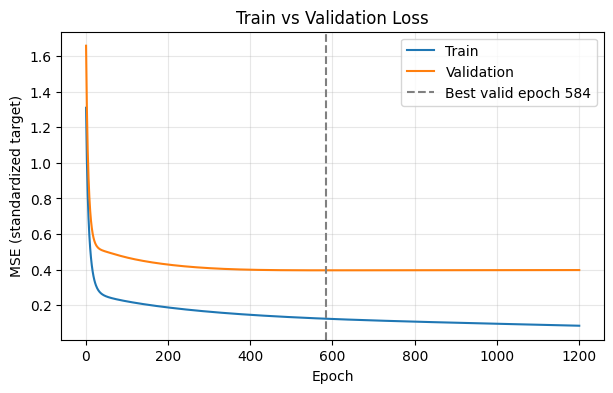

In [5]:
history, checkpoints = train_demo()
selected = history[history["epoch"].isin([1, 100, 200, 400, 600, 800, 1000, 1200])]
print(selected.round(6).to_string(index=False))

best_row = history.loc[history["valid_loss"].idxmin()]
print("\n검증 손실 최저 행 번호:", history["valid_loss"].idxmin())
print(f"최저 epoch: {int(best_row['epoch'])}, 학습 손실 {best_row['train_loss']:.6f}, 검증 손실 {best_row['valid_loss']:.6f}")
last = history.iloc[-1]
print(f"마지막 epoch {int(last['epoch'])}: 학습 손실 {last['train_loss']:.6f}, 검증 손실 {last['valid_loss']:.6f}")
print(f"최저 이후 검증 손실 증가량: {last['valid_loss'] - best_row['valid_loss']:.6f}")

plt.figure(figsize=(7, 4))
plt.plot(history["epoch"], history["train_loss"], label="Train")
plt.plot(history["epoch"], history["valid_loss"], label="Validation")
plt.axvline(best_row["epoch"], color="gray", linestyle="--", label=f"Best valid epoch {int(best_row['epoch'])}")
plt.xlabel("Epoch")
plt.ylabel("MSE (standardized target)")
plt.title("Train vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### 답변 작성란

**계산·결과 정리:**

- 출력값·배열 크기·비교 표: 주요 기록(표준화된 목표의 MSE): epoch 1 학습 1.309837 / 검증 1.658692, 100: 0.221291 / 0.467928, 200: 0.187021 / 0.428178, 400: 0.145534 / 0.399101, 600: 0.122144 / 0.395813, 800: 0.107144 / 0.396244, 1000: 0.095320 / 0.396382, 1200: 0.084271 / 0.397232. 검증 손실 최저 행은 DataFrame 행 번호 583, 즉 epoch 584(학습 0.123617, 검증 0.395805)입니다.
- 첫 값의 대입 과정 또는 판단 근거: history는 1200행(epoch 1부터 1200까지)이고, 행 번호는 0부터 시작하므로 행 583 = epoch 584입니다. 그래프에서 학습 손실은 끝까지 계속 내려가지만, 검증 손실은 약 600 epoch 근처에서 바닥을 찍은 뒤 거의 평평하거나 아주 조금씩 올라갑니다.

**Q1. 일반화와 과적합은 무엇인가요? 검증 손실까지 함께 봐야 하는 이유는 무엇인가요?**

- 내 답변: 일반화는 학습에 쓰지 않은 새 데이터에서도 예측이 잘 맞는 성질이고, 과적합은 학습 데이터에 지나치게 맞춰져 학습 손실은 계속 줄지만 새 데이터의 성능은 더 좋아지지 않거나 나빠지는 상태입니다. 학습 손실은 가중치를 맞춘 데이터에서 계산하므로 계속 줄어들기 쉬워, 새 데이터의 성능을 알려 주지 못합니다. 그래서 업데이트에 쓰지 않은 검증 손실을 함께 봐야 합니다.
- 수치 또는 코드에 근거한 이유: 학습 손실은 epoch 600 → 1200에서 0.122144 → 0.084271로 약 31% 더 줄었지만, 검증 손실은 0.395813 → 0.397232로 오히려 약간 늘었습니다. 학습 손실만 보면 계속 좋아지는 것처럼 보입니다.

**Q2. 검증 손실이 가장 작은 epoch와 그 값은 무엇인가요? 최저점 이후와 마지막 기록을 비교해 어떤 징후를 읽을 수 있나요?**

- 내 답변: 검증 손실이 가장 작은 epoch는 584이고 값은 약 0.395805입니다. 마지막 epoch 1200의 검증 손실은 0.397232로 최저보다 약 0.001428 커졌고, 같은 기간 학습 손실은 0.123617에서 0.084271로 계속 줄었습니다. 학습 손실은 계속 줄어드는데 검증 손실은 최저점 이후 조금씩 늘어나는, 약한 과적합의 징후로 읽을 수 있습니다.
- 수치 또는 코드에 근거한 이유: 검증 증가량 0.001428은 최저값의 약 0.36%로 작습니다. 따라서 '심한 과적합'보다는 '학습을 더 해도 일반화가 좋아지지 않고 약간 나빠지기 시작한 상태'로 보는 것이 적절합니다.

**Q3. 학습 손실보다 검증 손실이 높으면 언제나 심한 과적합인가요? 이번 검증 최저값을 최종 테스트 성능으로 발표해도 되나요?**

- 내 답변: 아닙니다. 학습 데이터에 맞춰 가중치를 고쳤으므로 학습 손실이 검증 손실보다 낮은 것은 흔하며, 그 차이만으로 심한 과적합이라고 판단하지 않습니다. 추세(학습 손실은 줄고 검증 손실은 늘어나는지)와 차이의 크기를 함께 봐야 합니다. 또 검증 최저값은 검증 데이터로 시점을 고르는 데 사용했으므로 선택 과정에 관여한 값이라, 최종 테스트 성능으로 발표하면 안 되고 별도의 테스트 데이터로 확인해야 합니다.
- 수치 또는 코드에 근거한 이유: epoch 1에서도 학습 1.309837 < 검증 1.658692로 학습 전부터 차이가 있었습니다. 이번 실습은 미사용 725행으로 테스트 평가를 하지 않았으며, 손실도 MPa 단위가 아닌 표준화된 목표의 MSE입니다.


### 문제 1-2. Dropout과 Weight Decay는 무엇을 바꿀까요?

#### 문제 설명

두 기법의 동작을 따로 계산합니다. Dropout은 활성값 H에, Weight Decay는 가중치 W의 업데이트에 적용합니다. 아래는 계산 원리 예시이며 진단용 학습 기록에 적용한 실험이 아닙니다.

**Dropout:** 제거 확률 p=0.5로 놓고 제공 마스크를 사용합니다. 1은 유지, 0은 제거입니다. 학습 중 유지한 값을 `1/(1−p)`배 하는 방식을 사용합니다.

$$H_{train}=H\times mask/(1-p),\qquad H_{eval}=H$$

마스크는 손계산을 위해 한 가지 결과로 고정했습니다. 실제 학습에서는 매번 무작위로 뽑으며 p=0.5라고 정확히 절반이 제거되는 것은 아닙니다. 평가에서는 이 방식의 Dropout을 끕니다.

**Weight Decay:** 기본 SGD에서 학습률 lr=0.1, 계수 λ=0.5, 설명용 가중치 기울기 G의 모든 값을 0.2로 가정합니다.

$$W_{plain}=W-lrG$$
$$W_{decay}=(1-lr\lambda)W-lrG$$

G는 업데이트 식을 따라가기 위한 **가정한 기울기**이며 실제 진단 모델에서 구한 기울기가 아닙니다. 이번에는 W만 비교하며 편향 b에는 decay를 적용하지 않습니다. 모든 Optimizer에서 같은 처리가 된다는 뜻은 아닙니다.

#### 요구사항

1. p=0.5일 때 H_train과 H_eval을 계산하고 H·mask와 함께 출력하세요.
2. G를 `np.full_like(W,0.2)`로 만든 뒤 W_plain·W_decay를 각각 원래 W에서 계산하세요.
3. H의 첫 행과 W의 첫 원소 1.0에 대해 손계산하세요.

#### 해석 질문

**Q1.** 첫 행 Dropout 결과는 무엇인가요? 유지된 값에 2를 곱하는 이유는 무엇인가요?

**Q2.** Dropout은 뉴런이나 가중치를 영구 삭제하나요? 평가에서도 같은 마스크와 2배 계산을 적용하나요?

**Q3.** W의 첫 값은 decay 전후 업데이트에서 각각 얼마인가요? decay 항이 하는 일과 전체 업데이트의 방향을 구분해서 설명하세요.

**Q4.** 두 기법이 과적합을 줄이는 데 도움이 되는 이유는 무엇인가요? 이 작은 계산으로 성능 향상이 입증되었나요?

#### 제출 결과

Dropout·가중치 업데이트 결과, 손계산, Q1~Q4 답변.


In [6]:
p = 0.5
H_train = H * mask / (1 - p)
H_eval = H.copy()

print("H:\n", np.round(H, 6))
print("mask:\n", mask)
print("H_train (p=0.5):\n", np.round(H_train, 6))
print("H_eval:\n", np.round(H_eval, 6))

G = np.full_like(W, 0.2)
lr = 0.1
decay = 0.5
W_plain = W - lr * G
W_decay = (1 - lr * decay) * W - lr * G

print("\nW:\n", W)
print("G:\n", G)
print("W_plain:\n", np.round(W_plain, 6))
print("W_decay:\n", np.round(W_decay, 6))
print(f"\n첫 원소: plain = 1.0 - 0.1×0.2 = {W_plain[0,0]:.4f}, decay = (1 - 0.1×0.5)×1.0 - 0.1×0.2 = {W_decay[0,0]:.4f}")

H:
 [[1.98   0.     3.41  ]
 [2.96   0.08   2.92  ]
 [2.927  0.5185 2.4815]
 [3.5755 0.779  2.221 ]]
mask:
 [[1 0 1]
 [0 1 0]
 [1 1 0]
 [0 0 1]]
H_train (p=0.5):
 [[3.96  0.    6.82 ]
 [0.    0.16  0.   ]
 [5.854 1.037 0.   ]
 [0.    0.    4.442]]
H_eval:
 [[1.98   0.     3.41  ]
 [2.96   0.08   2.92  ]
 [2.927  0.5185 2.4815]
 [3.5755 0.779  2.221 ]]

W:
 [[ 1.   0.5 -0.5]
 [ 0.5 -1.   1. ]]
G:
 [[0.2 0.2 0.2]
 [0.2 0.2 0.2]]
W_plain:
 [[ 0.98  0.48 -0.52]
 [ 0.48 -1.02  0.98]]
W_decay:
 [[ 0.93   0.455 -0.495]
 [ 0.455 -0.97   0.93 ]]

첫 원소: plain = 1.0 - 0.1×0.2 = 0.9800, decay = (1 - 0.1×0.5)×1.0 - 0.1×0.2 = 0.9300


#### 답변 작성란

**계산·결과 정리:**

- 출력값·배열 크기·비교 표: Dropout(p = 0.5): H_train = H × mask / 0.5 = [[3.96, 0, 6.82], [0, 0.16, 0], [5.854, 1.037, 0], [0, 0, 4.442]], H_eval = H = [[1.98, 0, 3.41], [2.96, 0.08, 2.92], [2.927, 0.5185, 2.4815], [3.5755, 0.779, 2.221]] (모두 4×3). Weight Decay(lr = 0.1, λ = 0.5, G = 0.2): W_plain = W - 0.02 = [[0.98, 0.48, -0.52], [0.48, -1.02, 0.98]], W_decay = 0.95 × W - 0.02 = [[0.93, 0.455, -0.495], [0.455, -0.97, 0.93]] (모두 2×3).
- 첫 값의 대입 과정 또는 판단 근거: H 첫 행 [1.98, 0, 3.41], mask 첫 행 [1, 0, 1] → [1.98 × 1, 0 × 0, 3.41 × 1] / 0.5 = [3.96, 0, 6.82]. W 첫 원소: W_plain = 1.0 - 0.1 × 0.2 = 0.98, W_decay = (1 - 0.1 × 0.5) × 1.0 - 0.1 × 0.2 = 0.95 - 0.02 = 0.93.

**Q1. 첫 행 Dropout 결과는 무엇인가요? 유지된 값에 2를 곱하는 이유는 무엇인가요?**

- 내 답변: 첫 행 Dropout 결과는 [3.96, 0, 6.82]입니다. 유지된 값에 1 / (1 - p) = 1 / 0.5 = 2를 곱하는 이유는, 학습 중 평균적으로 절반이 제거되어 다음 층으로 가는 값의 기대 크기가 줄어드는 것을 보정해, 평가 때(제거 없음)와 기대값의 크기를 맞추기 위해서입니다.
- 수치 또는 코드에 근거한 이유: 각 값이 확률 0.5로 남으면 기대값은 0.5 × (2 × h) + 0.5 × 0 = h가 되어 원래 값과 같아집니다. 둘째 값은 원래 0이라 마스크와 관계없이 0입니다.

**Q2. Dropout은 뉴런이나 가중치를 영구 삭제하나요? 평가에서도 같은 마스크와 2배 계산을 적용하나요?**

- 내 답변: 영구 삭제하지 않습니다. 학습 중 매 단계마다 무작위로 일부 활성값을 그 순간만 0으로 만들 뿐이며, 뉴런과 가중치는 그대로 남아 다음 단계에서는 다른 마스크가 적용됩니다. 평가 때는 마스크와 2배 보정을 모두 적용하지 않고 H를 그대로 사용합니다(H_eval = H).
- 수치 또는 코드에 근거한 이유: 코드에서 H_eval = H.copy()로 원래 값 그대로이며, 보정은 학습 단계에서 이미 했으므로(inverted dropout) 평가 때 다시 하지 않습니다.

**Q3. W의 첫 값은 decay 전후 업데이트에서 각각 얼마인가요? decay 항이 하는 일과 전체 업데이트의 방향을 구분해서 설명하세요.**

- 내 답변: W의 첫 값 1.0은 일반 업데이트에서 0.98, decay를 포함한 업데이트에서 0.93이 됩니다. decay 항 (1 - lr × λ) = 0.95는 기울기와 상관없이 가중치 자체를 0 방향으로 5% 줄이는 역할을 하고(1.0 → 0.95), 기울기 항 -lr × G = -0.02는 데이터 손실을 줄이는 방향으로 움직이게 합니다. 두 항을 합친 전체 업데이트는 0.07만큼 감소했습니다.
- 수치 또는 코드에 근거한 이유: decay 항이 하는 일: 1.0 × 0.95 = 0.95(0.05 감소). 기울기 항: -0.1 × 0.2 = -0.02. 합계 0.93. 음수 가중치 -0.5도 0.95배 하면 -0.475로 0 쪽으로 당겨지며, 여기에 기울기 항이 더해져 -0.495가 됩니다.

**Q4. 두 기법이 과적합을 줄이는 데 도움이 되는 이유는 무엇인가요? 이 작은 계산으로 성능 향상이 입증되었나요?**

- 내 답변: Dropout은 학습 중 특정 뉴런 조합에 지나치게 의존하지 못하게 해 여러 뉴런이 고르게 유용한 특징을 배우도록 하고, Weight Decay는 가중치가 지나치게 커지지 않게 눌러 모델을 더 단순하고 부드럽게 만들어, 둘 다 학습 데이터의 잡음까지 외우는 것을 줄이는 데 도움이 됩니다. 하지만 이 작은 계산은 동작 원리만 보여 준 것이고 진단용 모델 학습에는 적용하지 않았으므로 성능 향상은 입증되지 않았습니다.
- 수치 또는 코드에 근거한 이유: 검증 손실 비교 같은 실험을 하지 않았습니다. 성능 향상을 보이려면 같은 모델·데이터에서 기법을 켠 경우와 끈 경우의 검증(또는 테스트) 손실을 비교해야 합니다.


---

## 실습 2. 학습 안정화와 중단 시점


### 문제 2-1. Batch Normalization의 학습·평가 계산

#### 문제 설명

작은 층의 가중합 Z를 4개 샘플·3개 특징으로 구성된 배치라고 보고 BN을 계산합니다. Dropout 결과를 이어서 넣지 않고 **원래 Z**에서 시작합니다.

학습 시에는 각 특징 열에 대해 배치 평균 μ와 분산 v를 구합니다. 분산은 이번 계산에서 `ddof=0`을 사용합니다.

$$\hat Z=(Z-\mu)/\sqrt{v+\epsilon},\qquad BN(Z)=\gamma\hat Z+\beta$$

epsilon=0.00001, gamma=[1,1,1], beta=[0,0,0]으로 고정합니다. 실제 BN에서는 gamma와 beta를 학습할 수 있습니다.

평가 계산에는 **이미 학습 중 누적되었다고 가정한 예시 통계량** `running_mean=[4,1,2]`, `running_var=[1,0.25,0.5]`를 제공합니다. 이 값은 진단용 모델에서 구한 통계량이 아니며, 현재 배치의 평균·분산과도 다릅니다. 이 문제에서는 누적 과정 구현 대신 고정 통계량을 사용하는 원리만 확인합니다.

#### 요구사항

1. `Z.mean(axis=0)`, `Z.var(axis=0,ddof=0)`으로 열별 평균·분산을 구하세요.
2. x_hat과 BN 학습 결과를 계산하고 결과의 열별 평균·분산을 확인하세요.
3. 평가 입력은 `Z[:1]` 한 행으로 놓고, 제공한 running 통계량과 같은 gamma·beta로 계산하세요. 평가 입력에서 평균·분산을 새로 구하지 않습니다.
4. 첫 특징의 학습 정규화 값과 평가 값의 대입 식을 쓰세요.

#### 해석 질문

**Q1.** Z의 열별 평균과 분산은 무엇인가요? axis=0으로 계산하는 이유는 무엇인가요?

**Q2.** 첫 행 첫 특징의 학습 결과는 얼마인가요? 결과 평균·분산은 어떤 값에 가깝고, gamma·beta가 바뀌어도 항상 같은가요?

**Q3.** 첫 행 평가 결과는 무엇인가요? 학습 때와 다른 숫자가 나오는 이유는 무엇인가요?

**Q4.** BN은 평가 때 꺼지는 Dropout과 같나요? 입력 데이터 표준화와 같은 작업인가요? 과적합을 항상 해결하나요?

#### 제출 결과

배치 통계·학습 및 평가 결과, 대입 식, Q1~Q4 답변.


In [7]:
eps = 1e-5
gamma = np.ones(3)
beta = np.zeros(3)

batch_mean = Z.mean(axis=0)
batch_var = Z.var(axis=0, ddof=0)
x_hat = (Z - batch_mean) / np.sqrt(batch_var + eps)
bn_train = gamma * x_hat + beta

running_mean = np.array([4.0, 1.0, 2.0])
running_var = np.array([1.0, 0.25, 0.5])
bn_eval = gamma * (Z[:1] - running_mean) / np.sqrt(running_var + eps) + beta

print("Z:\n", np.round(Z, 6))
print("배치 평균:", np.round(batch_mean, 6))
print("배치 분산:", np.round(batch_var, 6))
print("bn_train:\n", np.round(bn_train, 6))
print("bn_train 열별 평균:", np.round(bn_train.mean(axis=0), 6))
print("bn_train 열별 분산:", np.round(bn_train.var(axis=0), 6))
print("평가 입력 Z[:1]:", np.round(Z[:1], 6))
print("bn_eval:", np.round(bn_eval, 6))
print(f"\n첫 특징 학습: ({Z[0,0]:.4f} - {batch_mean[0]:.4f}) / sqrt({batch_var[0]:.6f} + 0.00001) = {bn_train[0,0]:.6f}")
print(f"첫 특징 평가: ({Z[0,0]:.4f} - 4) / sqrt(1 + 0.00001) = {bn_eval[0,0]:.6f}")

Z:
 [[ 1.98   -0.41    3.41  ]
 [ 2.96    0.08    2.92  ]
 [ 2.927   0.5185  2.4815]
 [ 3.5755  0.779   2.221 ]]
배치 평균: [2.860625 0.241875 2.758125]
배치 분산: [0.325207 0.204042 0.204042]
bn_train:
 [[-1.544203 -1.443091  1.443091]
 [ 0.174257 -0.358351  0.358351]
 [ 0.116391  0.61238  -0.61238 ]
 [ 1.253555  1.189062 -1.189062]]
bn_train 열별 평균: [ 0. -0. -0.]
bn_train 열별 분산: [0.999969 0.999951 0.999951]
평가 입력 Z[:1]: [[ 1.98 -0.41  3.41]]
bn_eval: [[-2.01999  -2.819944  1.994021]]

첫 특징 학습: (1.9800 - 2.8606) / sqrt(0.325207 + 0.00001) = -1.544203
첫 특징 평가: (1.9800 - 4) / sqrt(1 + 0.00001) = -2.019990


#### 답변 작성란

**계산·결과 정리:**

- 출력값·배열 크기·비교 표: Z (4×3) = [[1.98, -0.41, 3.41], [2.96, 0.08, 2.92], [2.927, 0.5185, 2.4815], [3.5755, 0.779, 2.221]]. 배치 평균 = [2.860625, 0.241875, 2.758125], 배치 분산 = [0.325207, 0.204042, 0.204042]. bn_train (4×3) = [[-1.544203, -1.443091, 1.443091], [0.174257, -0.358351, 0.358351], [0.116391, 0.61238, -0.61238], [1.253555, 1.189062, -1.189062]], 열별 평균 = 약 [0, 0, 0], 열별 분산 = [0.999969, 0.999951, 0.999951]. bn_eval (1×3) = [-2.01999, -2.819944, 1.994021].
- 첫 값의 대입 과정 또는 판단 근거: 첫 특징 학습: (1.98 - 2.860625) / (0.325207 + 0.00001의 제곱근) = -0.880625 / 0.570278 = 약 -1.544203. 첫 특징 평가: (1.98 - 4) / (1 + 0.00001의 제곱근) = -2.02 / 1.000005 = 약 -2.01999.

**Q1. Z의 열별 평균과 분산은 무엇인가요? axis=0으로 계산하는 이유는 무엇인가요?**

- 내 답변: 열별 평균은 [2.860625, 0.241875, 2.758125], 분산은 [0.325207, 0.204042, 0.204042]입니다. BN은 각 특징(뉴런)마다 배치 안의 여러 샘플 값을 모아 정규화하므로, 행(샘플) 방향을 따라 같은 열의 값을 모으는 axis=0으로 계산합니다.
- 수치 또는 코드에 근거한 이유: 첫 열 평균 = (1.98 + 2.96 + 2.927 + 3.5755) / 4 = 11.4425 / 4 = 2.860625. axis=1로 하면 한 샘플 안의 서로 다른 특징을 섞어 버립니다.

**Q2. 첫 행 첫 특징의 학습 결과는 얼마인가요? 결과 평균·분산은 어떤 값에 가깝고, gamma·beta가 바뀌어도 항상 같은가요?**

- 내 답변: 첫 행 첫 특징의 학습 결과는 약 -1.544203입니다. gamma = 1, beta = 0일 때 결과의 열별 평균은 약 0, 분산은 약 1에 가깝습니다(분산이 정확히 1이 아닌 것은 분모의 ε 때문). gamma·beta가 바뀌면 결과 = gamma × x_hat + beta이므로 평균은 beta, 분산은 gamma의 제곱 근처로 바뀝니다. 항상 평균 0, 분산 1인 것은 아닙니다.
- 수치 또는 코드에 근거한 이유: bn_train 열별 평균 [0, 0, 0], 분산 [0.999969, 0.999951, 0.999951]. 예: gamma = 2, beta = 3이면 평균 3, 분산 약 4가 됩니다.

**Q3. 첫 행 평가 결과는 무엇인가요? 학습 때와 다른 숫자가 나오는 이유는 무엇인가요?**

- 내 답변: 첫 행 평가 결과는 [-2.01999, -2.819944, 1.994021]입니다. 학습 때는 현재 배치 4개 샘플의 평균·분산(첫 특징 2.860625, 0.325207)을 사용했지만, 평가 때는 학습 중 누적되었다고 가정한 running 통계량(첫 특징 4, 1)을 사용하므로 같은 입력 1.98이라도 -1.544203과 -2.01999로 다른 숫자가 나옵니다.
- 수치 또는 코드에 근거한 이유: 평가 때는 입력이 한 행뿐이라 배치 통계를 구하기 어렵고, 같은 입력에는 배치 구성과 관계없이 항상 같은 출력이 나와야 하므로 고정된 저장 통계를 씁니다.

**Q4. BN은 평가 때 꺼지는 Dropout과 같나요? 입력 데이터 표준화와 같은 작업인가요? 과적합을 항상 해결하나요?**

- 내 답변: 같지 않습니다. Dropout은 평가 때 완전히 꺼지지만, BN은 평가 때도 꺼지지 않고 저장 통계(running mean·variance)와 학습된 gamma·beta로 정규화를 계속 수행합니다. 입력 데이터 표준화는 학습 전에 원본 입력에 한 번 적용하는 고정된 전처리이고, BN은 신경망 안의 층에서 중간값을 배치 통계로 정규화하고 gamma·beta를 학습하는 층이므로 다릅니다. BN은 주로 학습 안정화에 도움이 되며 약간의 규제 효과가 있을 수 있지만, 과적합을 항상 해결하지는 않습니다.
- 수치 또는 코드에 근거한 이유: 이번 노트북에서도 입력 표준화(x_mean, x_std)와 BN(batch_mean, running_mean)은 서로 다른 단계에서 다른 통계로 계산했습니다.


### 문제 2-2. Early Stopping으로 멈출 때와 복원할 때 구분하기

#### 문제 설명

문제 1-1의 실제 기록과 체크포인트에 patience=20을 적용합니다. 최저 검증 손실보다 작은 값이 나오지 않은 epoch가 연속 20번이면 중단합니다. 중단 직전까지 본 정보만으로 판단합니다.

#### 요구사항

1. `replay_early_stopping(history,checkpoints,patience=20)`으로 요약·판단 기록·최적 파라미터를 받으세요.
2. 마지막으로 확인한 epoch, 최적 epoch, 최저 검증 손실을 출력하세요.
3. 판단 기록의 마지막 22행을 출력해 기다린 횟수가 어떻게 증가하는지 보세요.
4. 반환된 최적 파라미터를 `predict(X_valid,best_params)`에 넣어 MSE를 계산하고 저장된 최저 검증 손실과 비교하세요.

#### 작성 도움말

`result20,trace20,best_params=replay_early_stopping(...)`로 받습니다. 복원 검증 손실은 `np.mean((predict(X_valid,best_params)-y_valid)**2)`입니다. 기록만 최저로 표시하지 말고 해당 가중치의 예측 결과도 확인합니다.

#### 해석 질문

**Q1.** 중단 시점과 복원할 최적 epoch는 각각 언제인가요? 서로 다른 이유는 무엇인가요?

**Q2.** 기다린 횟수는 어떤 때 0으로 돌아가나요? patience=20은 전체 학습을 20 epoch만 한다는 뜻인가요?

**Q3.** 복원된 가중치로 계산한 검증 손실은 얼마인가요? 중단한 시점의 가중치를 그대로 쓰는 것과 무엇이 다른가요?

**Q4.** Early Stopping은 실제로 기울기나 모델 구조를 바꾸나요? 이번 기록 재생이 실제 학습 시간을 줄인 실험인가요?

#### 제출 결과

판단 요약·기다린 횟수 기록·복원 손실, Q1~Q4 답변.


In [8]:
result20, trace20, best_params = replay_early_stopping(history, checkpoints, patience=20)
print("요약:", result20)
print("마지막으로 확인한 epoch:", result20["last_checked_epoch"])
print("최적 epoch:", result20["best_epoch"])
print("최저 검증 손실:", round(result20["best_valid_loss"], 6))
print("\n판단 기록 마지막 22행:")
print(trace20.tail(22).round(6).to_string(index=False))

restored_loss = np.mean((predict(X_valid, best_params) - y_valid) ** 2)
print("\n복원한 가중치의 검증 손실:", round(restored_loss, 6))
print("저장된 최저값과 같은가:", np.isclose(restored_loss, result20["best_valid_loss"]))
stop_loss = history.loc[history["epoch"] == result20["last_checked_epoch"], "valid_loss"].iloc[0]
print("중단 시점 가중치의 검증 손실:", round(stop_loss, 6))

요약: {'stopped': True, 'last_checked_epoch': 604, 'best_epoch': 584, 'best_valid_loss': 0.3958047137386123}
마지막으로 확인한 epoch: 604
최적 epoch: 584
최저 검증 손실: 0.395805

판단 기록 마지막 22행:
 epoch  valid_loss  improved  wait  best_epoch
   583    0.395805      True     0         583
   584    0.395805      True     0         584
   585    0.395805     False     1         584
   586    0.395805     False     2         584
   587    0.395805     False     3         584
   588    0.395805     False     4         584
   589    0.395806     False     5         584
   590    0.395806     False     6         584
   591    0.395806     False     7         584
   592    0.395807     False     8         584
   593    0.395807     False     9         584
   594    0.395808     False    10         584
   595    0.395809     False    11         584
   596    0.395809     False    12         584
   597    0.395810     False    13         584
   598    0.395811     False    14         584
   599    0.395812     F

#### 답변 작성란

**계산·결과 정리:**

- 출력값·배열 크기·비교 표: patience = 20 결과: stopped = True, 마지막으로 확인한(중단) epoch = 604, 최적 epoch = 584, 최저 검증 손실 = 0.3958047. 판단 기록 마지막 22행에서 epoch 583·584는 improved = True(wait 0)이고, 585부터 604까지 wait가 1, 2, 3, …, 20으로 하나씩 증가해 20에 도달하자 중단했습니다. 복원한 가중치의 검증 손실 = 0.395805(저장된 최저값과 같음 True), 중단 시점(604) 가중치의 검증 손실 = 0.395817입니다.
- 첫 값의 대입 과정 또는 판단 근거: epoch 584의 검증 손실이 그때까지의 최저값보다 엄격히 작아 best_epoch = 584, wait = 0이 되었고, 이후 20 epoch 연속으로 더 작은 값이 나오지 않아 584 + 20 = 604에서 중단했습니다.

**Q1. 중단 시점과 복원할 최적 epoch는 각각 언제인가요? 서로 다른 이유는 무엇인가요?**

- 내 답변: 중단 시점은 epoch 604이고, 복원할 최적 epoch는 584입니다. Early Stopping은 '개선이 patience번 연속 없음'을 확인해야 멈출 수 있으므로, 최저점(584)을 지난 뒤 20 epoch를 더 기다린 시점에서야 멈춥니다. 그래서 멈추는 시점과 가장 좋았던 시점이 다릅니다.
- 수치 또는 코드에 근거한 이유: 중단 epoch = 최적 epoch + patience = 584 + 20 = 604.

**Q2. 기다린 횟수는 어떤 때 0으로 돌아가나요? patience=20은 전체 학습을 20 epoch만 한다는 뜻인가요?**

- 내 답변: 검증 손실이 지금까지의 최저값보다 엄격히 작아질 때(개선) wait가 0으로 돌아갑니다. patience = 20은 전체 학습을 20 epoch만 한다는 뜻이 아니라, 개선 없이 연속으로 기다릴 수 있는 횟수가 20이라는 뜻입니다. 이번에도 604 epoch까지 확인했습니다.
- 수치 또는 코드에 근거한 이유: 기록에서 583, 584 epoch는 improved = True로 wait = 0이었고, 이후 매 epoch마다 1씩 늘어 604에서 20이 되었습니다.

**Q3. 복원된 가중치로 계산한 검증 손실은 얼마인가요? 중단한 시점의 가중치를 그대로 쓰는 것과 무엇이 다른가요?**

- 내 답변: 복원한 가중치(epoch 584)로 계산한 검증 손실은 약 0.395805로 저장된 최저값과 같습니다. 중단 시점(604)의 가중치를 그대로 쓰면 검증 손실이 약 0.395817로, 기다리는 동안 조금 나빠진 상태의 모델을 쓰게 됩니다. 최적 가중치를 복원하면 검증 손실이 가장 낮았던 시점의 모델을 사용할 수 있습니다.
- 수치 또는 코드에 근거한 이유: 0.395817 - 0.395805 = 약 0.000012로 차이는 작지만, 복원해야 '가장 좋았던 시점'의 가중치를 정확히 쓸 수 있습니다. predict(X_valid, best_params)로 직접 다시 계산해 기록과 일치함을 확인했습니다.

**Q4. Early Stopping은 실제로 기울기나 모델 구조를 바꾸나요? 이번 기록 재생이 실제 학습 시간을 줄인 실험인가요?**

- 내 답변: 바꾸지 않습니다. Early Stopping은 기울기 계산 방식이나 모델 구조를 바꾸지 않고, 언제 학습을 멈추고 어느 시점의 가중치를 쓸지만 정하는 규칙입니다. 이번에는 1,200 epoch를 이미 모두 학습한 기록에 규칙을 재생했으므로 실제 학습 시간을 줄인 실험이 아닙니다. 시간을 줄이려면 이 판단을 학습 반복문 안에 넣어 604 epoch에서 실제로 멈춰야 합니다.
- 수치 또는 코드에 근거한 이유: train_demo()는 1,200 epoch를 끝까지 실행했고, replay_early_stopping()은 그 기록(history)과 체크포인트를 차례로 읽기만 했습니다.


---

## 기초 과제. 중단 규칙과 기법의 역할 복습


### 문제 3-1. 기다리는 횟수만 바꾸기

#### 문제 설명

같은 학습 기록과 체크포인트에 **patience=10**을 적용하세요. 다시 학습할 필요는 없습니다. 다른 조건과 엄격한 개선 판단 규칙은 유지합니다.

#### 요구사항

1. 제공 함수로 patience=10의 판단 요약과 최적 파라미터를 받으세요.
2. 복원한 검증 손실을 계산하세요.
3. patience=20과 10의 중단 시점·최적 시점·최저 손실을 표로 비교하세요.
4. Dropout·Weight Decay·Batch Normalization·Early Stopping이 각각 바꾸는 대상과 평가 때의 동작을 한 문장씩 정리하세요.

#### 해석 질문

**Q1.** patience=10의 중단 epoch, 최적 epoch, 복원 손실은 무엇인가요? patience=20과 어떤 차이가 있나요?

**Q2.** patience가 작을수록 항상 일반화 성능이 좋아지나요? 이번 결과를 근거로 설명하세요.

**Q3.** 네 기법의 역할과 평가 때의 동작을 각각 정리하세요. 이들을 모두 켜면 반드시 가장 좋은 모델이 되나요?

#### 제출 결과

두 설정 비교 표·복원 검증 손실·네 기법 역할 정리, Q1~Q3 답변.


In [9]:
result10, trace10, params10 = replay_early_stopping(history, checkpoints, patience=10)
loss10 = np.mean((predict(X_valid, params10) - y_valid) ** 2)
print("patience=10 요약:", result10)
print("복원 검증 손실:", round(loss10, 6))

compare = pd.DataFrame([
    {"patience": 20, "중단 epoch": result20["last_checked_epoch"], "최적 epoch": result20["best_epoch"],
     "최저 검증 손실": round(result20["best_valid_loss"], 6), "복원 검증 손실": round(restored_loss, 6)},
    {"patience": 10, "중단 epoch": result10["last_checked_epoch"], "최적 epoch": result10["best_epoch"],
     "최저 검증 손실": round(result10["best_valid_loss"], 6), "복원 검증 손실": round(loss10, 6)},
])
print(compare.to_string(index=False))
print("\npatience=10 판단 기록 마지막 12행:")
print(trace10.tail(12).round(6).to_string(index=False))

patience=10 요약: {'stopped': True, 'last_checked_epoch': 594, 'best_epoch': 584, 'best_valid_loss': 0.3958047137386123}
복원 검증 손실: 0.395805
 patience  중단 epoch  최적 epoch  최저 검증 손실  복원 검증 손실
       20       604       584  0.395805  0.395805
       10       594       584  0.395805  0.395805

patience=10 판단 기록 마지막 12행:
 epoch  valid_loss  improved  wait  best_epoch
   583    0.395805      True     0         583
   584    0.395805      True     0         584
   585    0.395805     False     1         584
   586    0.395805     False     2         584
   587    0.395805     False     3         584
   588    0.395805     False     4         584
   589    0.395806     False     5         584
   590    0.395806     False     6         584
   591    0.395806     False     7         584
   592    0.395807     False     8         584
   593    0.395807     False     9         584
   594    0.395808     False    10         584


#### 답변 작성란

**계산·결과 정리:**

- 출력값·배열 크기·비교 표: patience = 10: 중단 epoch 594, 최적 epoch 584, 최저 검증 손실 0.395805, 복원 검증 손실 0.395805.

| patience | 중단 epoch | 최적 epoch | 최저 검증 손실 | 복원 검증 손실 |
|---|---|---|---|---|
| 20 | 604 | 584 | 0.395805 | 0.395805 |
| 10 | 594 | 584 | 0.395805 | 0.395805 |

네 기법 정리: Dropout은 학습 중 활성값을 무작위로 일시 제거하고 평가 때는 끕니다. Weight Decay는 업데이트 때 가중치를 0 방향으로 줄이며, 평가 때는 업데이트가 없으므로 따로 동작하지 않습니다(이미 학습된 가중치만 사용). Batch Normalization은 중간값을 학습 때 배치 통계로, 평가 때 저장 통계로 정규화하고 gamma·beta를 적용합니다. Early Stopping은 학습을 멈출 시점과 복원할 가중치를 정하며, 평가 때는 복원된 최적 가중치를 사용합니다.
- 첫 값의 대입 과정 또는 판단 근거: 마지막 개선이 584 epoch이므로 patience = 10이면 584 + 10 = 594, patience = 20이면 584 + 20 = 604에서 중단합니다. 584 이후 검증 손실이 다시 최저를 갱신하지 않았기 때문에 두 설정 모두 같은 epoch 584를 복원했습니다.

**Q1. patience=10의 중단 epoch, 최적 epoch, 복원 손실은 무엇인가요? patience=20과 어떤 차이가 있나요?**

- 내 답변: patience = 10은 epoch 594에서 중단하고 epoch 584를 복원하며, 복원 검증 손실은 약 0.395805입니다. patience = 20과 비교하면 중단 시점만 10 epoch 빨라졌고 최적 epoch와 복원 손실은 같습니다.
- 수치 또는 코드에 근거한 이유: 두 설정 모두 best_epoch = 584, best_valid_loss = 0.3958047. 차이는 기다린 횟수뿐입니다.

**Q2. patience가 작을수록 항상 일반화 성능이 좋아지나요? 이번 결과를 근거로 설명하세요.**

- 내 답변: 그렇지 않습니다. 이번 결과에서는 patience 10과 20의 복원 손실이 0.395805로 완전히 같아 일반화 성능 차이가 없었고, 단지 더 일찍 멈췄을 뿐입니다. 만약 검증 손실이 잠시 오르다가 그 후에 다시 더 낮아지는 기록이었다면, patience가 작을 때 그 개선 전에 너무 일찍 멈춰 더 나쁜 시점을 복원할 수도 있습니다.
- 수치 또는 코드에 근거한 이유: 이번 기록은 584 이후 검증 손실이 거의 단조롭게 증가했기 때문에(585: 0.395805 → 604: 0.395817 → 1200: 0.397232) patience와 상관없이 같은 최적 시점이 선택되었습니다.

**Q3. 네 기법의 역할과 평가 때의 동작을 각각 정리하세요. 이들을 모두 켜면 반드시 가장 좋은 모델이 되나요?**

- 내 답변: Dropout: 학습 중 활성값을 무작위로 일시 제거해 특정 뉴런 의존을 줄이며, 평가 때는 꺼서 모든 값을 그대로 사용합니다. Weight Decay: 업데이트마다 가중치를 0 방향으로 줄여 가중치 크기를 제한하며, 평가 때는 별도 동작 없이 학습된 가중치를 씁니다. Batch Normalization: 층의 중간값을 정규화하고 gamma·beta로 조정해 학습을 안정화하며, 평가 때는 저장 통계로 계속 동작합니다. Early Stopping: 검증 손실이 개선되지 않으면 학습을 멈추고 최적 가중치를 복원하며, 평가 때는 복원된 가중치를 사용합니다. 이들을 모두 켠다고 반드시 가장 좋은 모델이 되지는 않으며, 설정값(p, λ, patience 등)과 데이터에 따라 성능이 오히려 나빠질 수도 있으므로 검증으로 비교해야 합니다.
- 수치 또는 코드에 근거한 이유: 이번 자료에서는 Dropout·Weight Decay·BN을 진단용 모델 학습에 적용하지 않았으므로, 켰을 때의 성능 향상은 확인하지 않았습니다. Early Stopping만 실제 기록에 적용했습니다.


## 실습 마무리

아래 문항은 실습에서 계산한 내용을 스스로 설명하는 **기초 복습**입니다. 새 모델 구현이나 심화 수식 유도를 요구하지 않습니다. 답변에는 숫자뿐 아니라 무엇을 계산했고 왜 그렇게 해석하는지도 적어 보세요.

### 마무리 질문

**마무리 Q1.** 일반화와 과적합을 구분하고, 이번 손실 기록에서 과적합 징후를 판단한 수치와 이유를 쓰세요. 학습 손실만 보면 어떤 점을 놓치나요?

**마무리 Q2.** H 첫 행 [1.98,0,3.41]과 마스크 [1,0,1], 제거 확률 0.5로 학습·평가 Dropout 결과를 구하세요. 두 배 보정의 뜻도 설명하세요.

**마무리 Q3.** w=1, 기울기 G=0.2, lr=0.1, decay=0.5일 때 일반 업데이트와 decay 포함 결과를 계산하세요. 음수 가중치에도 decay가 0 방향으로 작용하는 이유를 쓰세요.

**마무리 Q4.** BN에서 axis=0, epsilon, gamma·beta가 각각 무엇을 하는지 설명하세요. 첫 특징의 학습값과 평가값이 다른 이유와 평가에서도 BN이 필요한 이유를 쓰세요.

**마무리 Q5.** 584 epoch에서 마지막으로 개선된 뒤 개선이 없을 때 patience=20과 10은 각각 언제 중단하고 어느 시점을 복원하나요? 입력된 전체 기록을 미리 보고 중단하는 규칙인가요?

**마무리 Q6.** Dropout·Weight Decay·BN·Early Stopping을 바꾸는 대상과 평가 시 동작으로 비교하세요. 이번 자료에서 실제로 검증한 내용과 아직 입증하지 않은 내용을 구분하세요.

### 마무리 답변 작성란

**마무리 Q1. 일반화와 과적합을 구분하고, 이번 손실 기록에서 과적합 징후를 판단한 수치와 이유를 쓰세요. 학습 손실만 보면 어떤 점을 놓치나요?**

- 내 답변: 일반화는 처음 보는 데이터에서도 예측이 잘 맞는 성질, 과적합은 학습 데이터에만 지나치게 맞아 새 데이터 성능이 좋아지지 않거나 나빠지는 상태입니다. 이번 기록에서 학습 손실은 epoch 584의 0.123617에서 1200의 0.084271로 계속 줄었지만, 검증 손실은 584의 최저 0.395805에서 1200의 0.397232로 조금 늘어 약한 과적합 징후로 판단했습니다. 학습 손실만 보면 계속 좋아지는 것처럼 보여 새 데이터 성능이 멈추거나 나빠지는 시점을 놓칩니다.
- 계산·비교 근거: 검증 증가량 0.397232 - 0.395805 = 0.001428(최저값 대비 약 0.36%), 같은 기간 학습 손실 감소 0.123617 - 0.084271 = 0.039346.

**마무리 Q2. H 첫 행 [1.98,0,3.41]과 마스크 [1,0,1], 제거 확률 0.5로 학습·평가 Dropout 결과를 구하세요. 두 배 보정의 뜻도 설명하세요.**

- 내 답변: 학습 Dropout 결과는 [1.98, 0, 3.41] × [1, 0, 1] / (1 - 0.5) = [1.98, 0, 3.41] × 2 = [3.96, 0, 6.82]이고, 평가 결과는 원래 값 그대로 [1.98, 0, 3.41]입니다. 두 배 보정은 학습 중 약 절반이 제거되어 줄어든 출력의 기대 크기를 평가 때(제거 없음)와 같게 맞추기 위한 것입니다.
- 계산·비교 근거: 1.98 × 1 / 0.5 = 3.96, 0 × 0 / 0.5 = 0, 3.41 × 1 / 0.5 = 6.82. 기대값: 0.5 × 3.96 + 0.5 × 0 = 1.98로 원래 값과 같음.

**마무리 Q3. w=1, 기울기 G=0.2, lr=0.1, decay=0.5일 때 일반 업데이트와 decay 포함 결과를 계산하세요. 음수 가중치에도 decay가 0 방향으로 작용하는 이유를 쓰세요.**

- 내 답변: 일반 업데이트는 1 - 0.1 × 0.2 = 0.98, decay 포함은 (1 - 0.1 × 0.5) × 1 - 0.1 × 0.2 = 0.95 - 0.02 = 0.93입니다. decay 항은 가중치에 1보다 작은 수 0.95를 곱하는 것이므로, 양수든 음수든 크기(절댓값)가 5% 줄어 항상 0 쪽으로 당겨집니다.
- 계산·비교 근거: 음수 예: w = -0.5이면 0.95 × (-0.5) = -0.475로 0에 가까워지고, 기울기 항까지 더하면 -0.475 - 0.02 = -0.495입니다(W_decay의 [0, 2] 원소).

**마무리 Q4. BN에서 axis=0, epsilon, gamma·beta가 각각 무엇을 하는지 설명하세요. 첫 특징의 학습값과 평가값이 다른 이유와 평가에서도 BN이 필요한 이유를 쓰세요.**

- 내 답변: axis=0은 배치 안의 샘플들(행)에 걸쳐 같은 특징(열)의 평균·분산을 구하게 합니다. epsilon은 분산이 0에 가까울 때 0으로 나누는 것을 막기 위해 분산에 더하는 아주 작은 양수입니다. gamma·beta는 정규화된 값의 크기와 위치를 다시 조절하는 학습 가능한 값으로, 필요하면 원래 분포에 가깝게 되돌릴 수도 있게 합니다. 첫 특징의 학습값(-1.544203)과 평가값(-2.01999)이 다른 이유는 학습 때는 현재 배치 통계(평균 2.860625, 분산 0.325207)를, 평가 때는 저장 통계(평균 4, 분산 1)를 쓰기 때문입니다. 평가에서도 BN이 필요한 이유는 모델이 정규화된 값을 기준으로 학습되었으므로, 평가 때도 같은 형태의 정규화를 해야 다음 층이 학습 때와 비슷한 크기의 입력을 받기 때문입니다.
- 계산·비교 근거: 학습: (1.98 - 2.860625) / (0.325217의 제곱근) = -0.880625 / 0.570278 = 약 -1.5442. 평가: (1.98 - 4) / (1.00001의 제곱근) = 약 -2.02.

**마무리 Q5. 584 epoch에서 마지막으로 개선된 뒤 개선이 없을 때 patience=20과 10은 각각 언제 중단하고 어느 시점을 복원하나요? 입력된 전체 기록을 미리 보고 중단하는 규칙인가요?**

- 내 답변: patience = 20은 584 + 20 = 604 epoch에서, patience = 10은 584 + 10 = 594 epoch에서 중단하고, 둘 다 검증 손실이 가장 낮았던 584 epoch의 가중치를 복원합니다. 이 규칙은 전체 기록을 미리 보고 최저점을 고르는 것이 아니라, 시간 순서대로 지금까지 본 정보만으로 '개선 여부와 기다린 횟수'를 판단해 중단합니다.
- 계산·비교 근거: replay_early_stopping은 history를 처음부터 한 행씩 읽고, wait >= patience가 되는 순간 break로 이후 기록(605부터 1200까지, 또는 595부터 1200까지)을 읽지 않았습니다.

**마무리 Q6. Dropout·Weight Decay·BN·Early Stopping을 바꾸는 대상과 평가 시 동작으로 비교하세요. 이번 자료에서 실제로 검증한 내용과 아직 입증하지 않은 내용을 구분하세요.**

- 내 답변: Dropout은 활성값을 바꾸며 평가 때 꺼지고, Weight Decay는 가중치 업데이트를 바꾸며 평가 때 별도 동작이 없고, BN은 중간값의 분포를 바꾸며 평가 때 저장 통계로 계속 동작하고, Early Stopping은 학습 기간과 사용할 가중치 시점을 바꾸며 평가 때 복원된 가중치를 씁니다. 이번 자료에서 실제로 검증한 것은 진단용 모델의 학습·검증 손실 추세(약한 과적합 징후), Early Stopping의 중단·복원 시점과 복원 손실 일치, 그리고 세 기법의 작은 동작 계산 결과입니다. 세 기법을 실제 모델에 적용했을 때 검증 성능이 좋아지는지, 그리고 별도 테스트 데이터에서의 최종 성능은 아직 입증하지 않았습니다.
- 계산·비교 근거: 검증한 수치: 최저 검증 0.395805(epoch 584), 복원 손실 0.395805 일치, H_train 첫 행 [3.96, 0, 6.82], W_decay 첫 값 0.93, BN 학습 결과 열별 평균 0·분산 약 1. 미검증: 기법 적용 전후 성능 비교, 테스트 성능.


### 학습 완료 확인

- [ ] 학습·검증 손실의 차이와 변화 추세를 함께 설명할 수 있습니다.
- [ ] Dropout에서 제거 확률·마스크·보정 배율·평가 동작을 구분합니다.
- [ ] Weight Decay 항의 방향과 전체 업데이트 방향을 구분합니다.
- [ ] BN의 배치 통계와 저장 통계, gamma·beta의 역할을 설명할 수 있습니다.
- [ ] Early Stopping의 중단 시점과 최적 가중치 복원 시점을 구분합니다.
- [ ] 이번 자료의 동작 계산과 성능 비교 여부를 정확히 말할 수 있습니다.

예시 문장과 똑같이 쓰지 않아도 됩니다. 값·배열 크기·동작 대상·이유가 맞는지를 확인하세요. 모호한 항목은 해당 문제의 코드 해석과 수치 예제로 돌아가 다시 정리합니다.


## 제출 전 확인

- 실습 2개와 기초 과제의 모든 질문에 답했나요?
- 학습 손실과 검증 손실을 함께 해석했나요?
- Dropout과 BN의 평가 동작을 구분했나요?
- 중단 시점과 복원 시점을 구분했나요?
- 실제 학습 기록과 설명용 가정값을 구분했나요?

## 주제별 이해 확인

| 주제 | 스스로 설명할 내용 |
|---|---|
| 일반화·과적합 | 학습 손실만으로 새 데이터의 성능을 판단할 수 없는 이유와 이번 곡선의 작은 악화 |
| Dropout | 마스크와 유지값 보정 계산, 일시적 제거, 평가에서 보정을 다시 하지 않는 이유 |
| Weight Decay | 기울기 항과 decay 항의 구분, 양수·음수 가중치를 0 방향으로 당긴다는 의미 |
| BN | 열별 평균·분산, epsilon·gamma·beta의 역할, 학습·평가 통계 차이 |
| Early Stopping | 새로운 최저값과 wait 초기화, patience 비교, 중단 시점과 복원 시점의 차이 |

계산값을 쓰는 데서 끝내지 말고 무엇을 계산했는지와 그 결과가 왜 나왔는지를 쉬운 말로 덧붙이세요. 답안 문장이 예시와 완전히 같을 필요는 없습니다. 이 자료는 제공된 강의 목차와 기존 실습을 기준으로 보완했으며, 별도로 제공되지 않은 교안 본문과의 세부 일치 여부까지 확인한 것은 아닙니다.
